# Task 2 - Autoformer Forecasting

Forecast the next 168 observations of the anonymized target series using Autoformer. The experiments first select the moving-average width using the complete external-data model and then ablate the external variables.

## Setup

In [13]:
import copy
import math
import random
import time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

from autoformer import Autoformer

DATA_DIR = Path("data")
CHECKPOINT_DIR = Path("checkpoints")
FIGURE_DIR = Path("outputs/figures")
TRAINING_FIGURE_DIR = FIGURE_DIR / "training_curves"
METRIC_DIR = Path("outputs/metrics")
OUTPUT_DIR = Path("outputs")

for directory in [CHECKPOINT_DIR, FIGURE_DIR, TRAINING_FIGURE_DIR, METRIC_DIR, OUTPUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [14]:
@dataclass
class Configuration:
    input_length: int = 672
    label_length: int = 168
    pred_length: int = 168
    external_dim: int = 0
    output_dim: int = 1
    d_model: int = 32
    n_heads: int = 4
    encoder_layers: int = 2
    decoder_layers: int = 1
    d_ff: int = 128
    moving_avg: int = 25
    delay_factor: float = 2.0
    dropout: float = 0.1
    activation: str = "gelu"
    batch_size: int = 64
    learning_rate: float = 1e-3
    max_epochs: int = 3
    min_delta: float = 1e-4
    gradient_clip: float = 1.0
    training_stride: int = 1

config = Configuration()
RESUME = False
TRAIN_END = 39288
WIDTHS = [13, 25, 49]
WIDTH_SEEDS = [0, 1]
EXTERNAL_SEEDS = [0, 1, 2]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

## Autoformer Smoke Test

In [15]:
def smoke_test(config, device):
    B = 2
    target_config = replace(config, external_dim=0)
    target_model = Autoformer(target_config).to(device)
    past_values = torch.randn(B, target_config.input_length, 1, device=device)

    seasonal, trend = target_model.decomposition(past_values)
    assert torch.allclose(seasonal + trend, past_values, atol=1e-6)
    prediction = target_model(past_values)
    assert prediction.shape == (B, target_config.pred_length, 1)
    assert torch.isfinite(prediction).all()

    prediction.square().mean().backward()
    gradients = [parameter.grad for parameter in target_model.parameters() if parameter.requires_grad]
    assert all(gradient is not None for gradient in gradients)
    assert all(torch.isfinite(gradient).all() for gradient in gradients)

    external_config = replace(config, external_dim=10)
    external_model = Autoformer(external_config).to(device)
    past_external = torch.randn(B, external_config.input_length, 10, device=device)
    future_external = torch.randn(B, external_config.pred_length, 10, device=device)
    external_prediction = external_model(past_values, past_external, future_external)
    assert external_prediction.shape == (B, external_config.pred_length, 1)
    assert torch.isfinite(external_prediction).all()
    print("Autoformer smoke test passed.")

smoke_test(config, device)

Autoformer smoke test passed.


## Dataset Initialization

In [16]:
train_df = pd.read_csv(DATA_DIR / "student_train.csv")
test_df = pd.read_csv(DATA_DIR / "student_test.csv")
external_df = pd.read_csv(DATA_DIR / "optional_external_data.csv")

target_values = train_df["value"].to_numpy(dtype=np.float32)
external_columns = [column for column in external_df.columns if column != "time_idx"]
external_values = external_df[external_columns].to_numpy(dtype=np.float32)
validation_origins = np.arange(TRAIN_END, len(target_values), config.pred_length)

print("Training observations:", TRAIN_END)
print("Validation observations:", len(target_values) - TRAIN_END)
print("Validation blocks:", len(validation_origins))
print("Test observations:", len(test_df))
print(f"Target mean: {target_values.mean():.4f}")
print(f"Target standard deviation: {target_values.std():.4f}")
print(f"Target minimum: {target_values.min():.4f}")
print(f"Target maximum: {target_values.max():.4f}")

Training observations: 39288
Validation observations: 4368
Validation blocks: 26
Test observations: 168
Target mean: 98.1735
Target standard deviation: 90.8337
Target minimum: 0.0000
Target maximum: 994.0000


## Dataset Characteristics

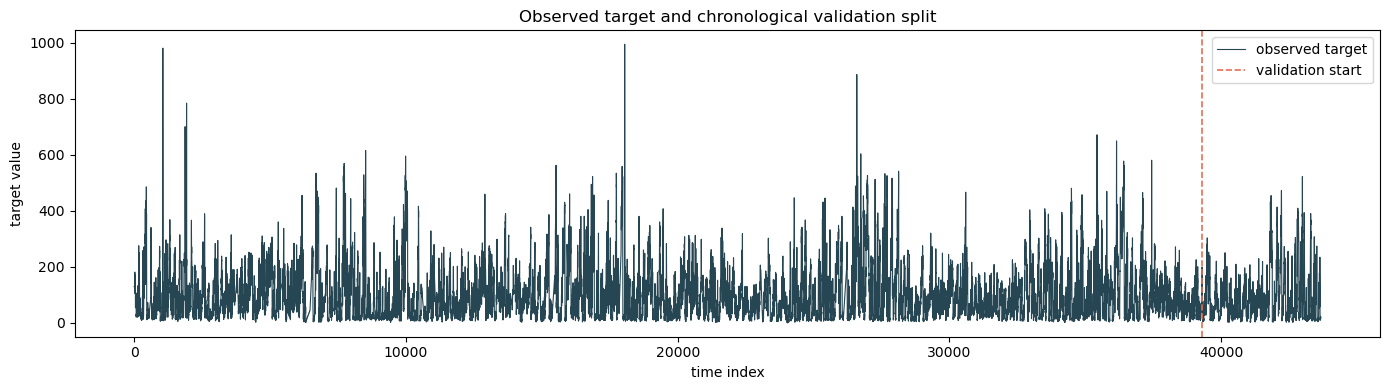

In [17]:
fig, axis = plt.subplots(figsize=(14, 4))
axis.plot(train_df["time_idx"], target_values, color="#264653", linewidth=0.8, label="observed target")
axis.axvline(TRAIN_END, color="#e76f51", linestyle="--", linewidth=1.2, label="validation start")
axis.set_xlabel("time index")
axis.set_ylabel("target value")
axis.set_title("Observed target and chronological validation split")
axis.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "target_series.png", dpi=300, bbox_inches="tight")
plt.show()

## Scaling and Window Construction

In [18]:
class DatasetScaler:
    def fit(self, values):
        self.mean = np.mean(values, axis=0, keepdims=True)
        self.std = np.std(values, axis=0, keepdims=True)
        self.std = np.where(self.std == 0, 1, self.std)
        return self

    def transform(self, values):
        return ((values - self.mean) / self.std).astype(np.float32)

    def inverse_transform(self, values):
        return values * self.std + self.mean

    def state_dict(self):
        return {"mean": self.mean, "std": self.std}


class ExternalScaler:
    def __init__(self, continuous_dim=6):
        self.continuous_dim = continuous_dim

    def fit(self, values):
        continuous = values[:, :self.continuous_dim]
        self.mean = np.mean(continuous, axis=0, keepdims=True)
        self.std = np.std(continuous, axis=0, keepdims=True)
        self.std = np.where(self.std == 0, 1, self.std)
        return self

    def transform(self, values):
        output = values.astype(np.float32).copy()
        output[:, :self.continuous_dim] = (output[:, :self.continuous_dim] - self.mean) / self.std
        return output

    def state_dict(self):
        return {"continuous_dim": self.continuous_dim, "mean": self.mean, "std": self.std}


target_scaler = DatasetScaler().fit(target_values[:TRAIN_END, None])
external_scaler = ExternalScaler().fit(external_values[:TRAIN_END])
scaled_target = target_scaler.transform(target_values[:, None])
scaled_external = external_scaler.transform(external_values)

In [19]:
class TimeSeriesDataset(Dataset):
    def __init__(self, target, external, input_length, pred_length, origins):
        self.target = target
        self.external = external
        self.input_length = input_length
        self.pred_length = pred_length
        self.origins = np.asarray(origins)

    def __len__(self):
        return len(self.origins)

    def __getitem__(self, index):
        origin = self.origins[index]
        context_start = origin - self.input_length
        target_end = origin + self.pred_length
        past_values = torch.from_numpy(self.target[context_start:origin])
        past_external = torch.from_numpy(self.external[context_start:origin])
        future_external = torch.from_numpy(self.external[origin:target_end])
        target = torch.from_numpy(self.target[origin:target_end])
        return past_values, past_external, future_external, target


def build_loaders(config, seed, target=scaled_target, external=scaled_external, train_end=TRAIN_END):
    train_origins = np.arange(config.input_length, train_end - config.pred_length + 1, config.training_stride)
    train_dataset = TimeSeriesDataset(target, external, config.input_length, config.pred_length, train_origins)
    validation_dataset = TimeSeriesDataset(target, external, config.input_length, config.pred_length, validation_origins)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_dataset, batch_size=config.batch_size, shuffle=True, generator=generator, pin_memory=device.type == "cuda")
    validation_loader = DataLoader(validation_dataset, batch_size=1, shuffle=False, pin_memory=device.type == "cuda")
    return train_loader, validation_loader

train_loader, validation_loader = build_loaders(config, seed=0)
print("Training windows:", len(train_loader.dataset))
print("Validation windows:", len(validation_loader.dataset))

Training windows: 38449
Validation windows: 26


## One-Batch Overfitting Test

This diagnostic repeatedly trains on one fixed batch from the initialized training loader. A large loss reduction confirms that gradients can update the model and that it has enough capacity to fit a small sample.

In [20]:
def one_batch_overfit_test(config, train_loader, device, steps=200):
    set_seed(0)
    diagnostic_config = replace(config, external_dim=0, dropout=0.0)
    past_values, _, _, targets = next(iter(train_loader))
    past_values = past_values[:8].to(device)
    targets = targets[:8].to(device)
    model = Autoformer(diagnostic_config).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    model.train()

    with torch.no_grad():
        initial_loss = criterion(model(past_values), targets).item()

    progress = tqdm(range(steps), desc="One-batch overfit")
    for _ in progress:
        optimizer.zero_grad(set_to_none=True)
        predictions = model(past_values)
        loss = criterion(predictions, targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), diagnostic_config.gradient_clip)
        optimizer.step()
        progress.set_postfix(mse=f"{loss.item():.6f}")

    model.train()
    with torch.no_grad():
        final_train_predictions = model(past_values)
        final_train_loss = criterion(final_train_predictions, targets).item()

    model.eval()
    with torch.no_grad():
        final_eval_predictions = model(past_values)
        final_eval_loss = criterion(final_eval_predictions, targets).item()

    reduction = 100 * (1 - final_train_loss / initial_loss)
    forecast_std = final_eval_predictions.std(dim=1).mean().item()
    print(f"Initial MSE: {initial_loss:.6f}")
    print(f"Final training-mode MSE: {final_train_loss:.6f}")
    print(f"Final evaluation-mode MSE: {final_eval_loss:.6f}")
    print(f"Loss reduction: {reduction:.2f}%")
    print(f"Mean forecast standard deviation: {forecast_std:.6f}")
    assert np.isfinite(final_train_loss)
    assert np.isfinite(final_eval_loss)
    assert final_train_loss < initial_loss * 0.2
    print("One-batch overfitting test passed.")

    del model, optimizer, past_values, targets, final_train_predictions, final_eval_predictions
    if device.type == "cuda":
        torch.cuda.empty_cache()

one_batch_overfit_test(config, train_loader, device)

One-batch overfit: 100%|██████████| 200/200 [00:16<00:00, 12.49it/s, mse=0.075299]

Initial MSE: 0.810285
Final training-mode MSE: 0.074454
Final evaluation-mode MSE: 0.428725
Loss reduction: 90.81%
Mean forecast standard deviation: 0.359951
One-batch overfitting test passed.


## Metrics and Training

In [21]:
def calculate_metrics(target, prediction):
    error = prediction - target
    rmse = float(np.sqrt(np.mean(error ** 2)))
    mae = float(np.mean(np.abs(error)))
    smape = float(100 * np.mean(2 * np.abs(error) / (np.abs(target) + np.abs(prediction) + 1e-8)))
    return {"rmse": rmse, "mae": mae, "smape": smape}

def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

In [22]:
class AutoformerTrainer:
    def __init__(self, model, config, target_scaler, external_scaler, checkpoint_path, device, name):
        self.model = model
        self.config = config
        self.target_scaler = target_scaler
        self.external_scaler = external_scaler
        self.checkpoint_path = checkpoint_path
        self.device = device
        self.name = name
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=config.learning_rate, betas=(0.9, 0.999), weight_decay=0)

    def train_epoch(self, train_loader, use_external, epoch):
        self.model.train()
        total_squared_error = 0
        total_points = 0
        target_scale = float(self.target_scaler.std.squeeze())
        progress = tqdm(train_loader, desc=f"{self.name} | epoch {epoch + 1}/{self.config.max_epochs}")

        for past_values, past_external, future_external, target in progress:
            past_values = past_values.to(self.device, non_blocking=True)
            target = target.to(self.device, non_blocking=True)
            past_external = past_external.to(self.device, non_blocking=True)
            future_external = future_external.to(self.device, non_blocking=True)
            self.optimizer.zero_grad(set_to_none=True)
            prediction = self.model(past_values, past_external, future_external) if use_external else self.model(past_values)
            loss = self.criterion(prediction, target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.config.gradient_clip)
            self.optimizer.step()
            total_squared_error += torch.sum((prediction.detach() - target) ** 2).item()
            total_points += target.numel()
            running_mse = total_squared_error / total_points
            running_rmse = math.sqrt(running_mse) * target_scale
            progress.set_postfix(mse=f"{running_mse:.5f}", rmse=f"{running_rmse:.4f}")

        return {"mse_loss": total_squared_error / total_points, "rmse": math.sqrt(total_squared_error / total_points) * target_scale}

    @torch.no_grad()
    def evaluate(self, validation_loader, use_external):
        self.model.eval()
        predictions = []
        targets = []
        total_scaled_squared_error = 0
        total_physical_squared_error = 0
        total_points = 0
        progress = tqdm(validation_loader, desc=f"{self.name} | validation", leave=False)

        for past_values, past_external, future_external, target in progress:
            past_values = past_values.to(self.device, non_blocking=True)
            past_external = past_external.to(self.device, non_blocking=True)
            future_external = future_external.to(self.device, non_blocking=True)
            prediction = self.model(past_values, past_external, future_external) if use_external else self.model(past_values)
            scaled_prediction = prediction.cpu().numpy()
            scaled_target = target.numpy()
            physical_prediction = self.target_scaler.inverse_transform(scaled_prediction.reshape(-1, 1)).reshape(scaled_prediction.shape)
            physical_target = self.target_scaler.inverse_transform(scaled_target.reshape(-1, 1)).reshape(scaled_target.shape)
            physical_prediction = np.clip(physical_prediction, 0, None)
            total_scaled_squared_error += float(np.sum((scaled_prediction - scaled_target) ** 2))
            total_physical_squared_error += float(np.sum((physical_prediction - physical_target) ** 2))
            total_points += scaled_target.size
            progress.set_postfix(mse=f"{total_scaled_squared_error / total_points:.5f}", rmse=f"{math.sqrt(total_physical_squared_error / total_points):.4f}")
            predictions.append(scaled_prediction)
            targets.append(scaled_target)

        predictions = np.concatenate(predictions, axis=0)
        targets = np.concatenate(targets, axis=0)
        predictions = self.target_scaler.inverse_transform(predictions.reshape(-1, 1)).reshape(predictions.shape)
        targets = self.target_scaler.inverse_transform(targets.reshape(-1, 1)).reshape(targets.shape)
        predictions = np.clip(predictions, 0, None)
        metrics = calculate_metrics(targets, predictions)
        metrics["mse_loss"] = total_scaled_squared_error / total_points
        return metrics, predictions, targets

    def save_checkpoint(self, epoch, best_epoch, best_rmse, history, best_model_state, training_seconds):
        checkpoint = {"model_state": self.model.state_dict(), "best_model_state": best_model_state, "optimizer_state": self.optimizer.state_dict(), "epoch": epoch, "best_epoch": best_epoch, "best_validation_rmse": best_rmse, "history": history, "training_seconds": training_seconds, "configuration": asdict(self.config), "target_scaler": self.target_scaler.state_dict(), "external_scaler": self.external_scaler.state_dict()}
        torch.save(checkpoint, self.checkpoint_path)

    def fit(self, train_loader, validation_loader, use_external=False, resume=False):
        start_epoch, best_epoch = 0, -1
        best_rmse, training_seconds = math.inf, 0
        history = {"train_mse_loss": [], "train_rmse": [], "validation_mse_loss": [], "validation_rmse": [], "validation_mae": [], "validation_smape": []}
        best_model_state = copy.deepcopy(self.model.state_dict())

        if resume and self.checkpoint_path.exists():
            checkpoint = torch.load(self.checkpoint_path, map_location=self.device)
            self.model.load_state_dict(checkpoint["model_state"])
            self.optimizer.load_state_dict(checkpoint["optimizer_state"])
            start_epoch = checkpoint["epoch"] + 1
            best_epoch = checkpoint["best_epoch"]
            best_rmse = checkpoint["best_validation_rmse"]
            history = checkpoint["history"]
            best_model_state = checkpoint["best_model_state"]
            training_seconds = checkpoint["training_seconds"]
            history.setdefault("train_mse_loss", history.pop("train_loss", []))
            history.setdefault("train_rmse", [math.sqrt(value) * float(self.target_scaler.std.squeeze()) for value in history["train_mse_loss"]])
            history.setdefault("validation_mse_loss", [(value / float(self.target_scaler.std.squeeze())) ** 2 for value in history["validation_rmse"]])

        for epoch in range(start_epoch, self.config.max_epochs):
            start_time = time.perf_counter()
            train_metrics = self.train_epoch(train_loader, use_external, epoch)
            metrics, _, _ = self.evaluate(validation_loader, use_external)
            training_seconds += time.perf_counter() - start_time
            history["train_mse_loss"].append(train_metrics["mse_loss"])
            history["train_rmse"].append(train_metrics["rmse"])
            history["validation_mse_loss"].append(metrics["mse_loss"])
            history["validation_rmse"].append(metrics["rmse"])
            history["validation_mae"].append(metrics["mae"])
            history["validation_smape"].append(metrics["smape"])

            if metrics["rmse"] < best_rmse - self.config.min_delta:
                best_rmse = metrics["rmse"]
                best_epoch = epoch
                best_model_state = copy.deepcopy(self.model.state_dict())

            self.save_checkpoint(epoch, best_epoch, best_rmse, history, best_model_state, training_seconds)
            print(f"Epoch {epoch + 1}: train MSE={train_metrics['mse_loss']:.5f}, train RMSE={train_metrics['rmse']:.4f}, validation MSE={metrics['mse_loss']:.5f}, validation RMSE={metrics['rmse']:.4f}")

        self.model.load_state_dict(best_model_state)
        metrics, predictions, targets = self.evaluate(validation_loader, use_external)
        result = {"train_mse_loss": history["train_mse_loss"][best_epoch], "train_rmse": history["train_rmse"][best_epoch], "validation_mse_loss": metrics["mse_loss"], "validation_rmse": metrics["rmse"], "validation_mae": metrics["mae"], "validation_smape": metrics["smape"], "best_epoch": best_epoch + 1, "parameters": count_parameters(self.model), "training_seconds": training_seconds}
        return result, history, predictions, targets

In [23]:
def save_training_history(name, history):
    history_df = pd.DataFrame(history)
    history_df.index = np.arange(1, len(history_df) + 1)
    history_df.index.name = "epoch"
    history_df.to_csv(METRIC_DIR / f"{name}_history.csv")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df.index, history_df["train_mse_loss"], label="train MSE")
    axes[0].plot(history_df.index, history_df["validation_mse_loss"], label="validation MSE")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("MSE loss")
    axes[0].set_title("Training and validation MSE")
    axes[0].legend()
    axes[1].plot(history_df.index, history_df["train_rmse"], label="train RMSE")
    axes[1].plot(history_df.index, history_df["validation_rmse"], label="validation RMSE")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("RMSE")
    axes[1].set_title("Training and validation RMSE")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(TRAINING_FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.close(fig)


def run_experiment(name, experiment_config, seed, use_external=False, resume=RESUME):
    set_seed(seed)
    print()
    print("Experiment:", name)
    print("Seed:", seed)
    print("Moving-average width:", experiment_config.moving_avg)
    print("External data:", use_external)
    train_loader, validation_loader = build_loaders(experiment_config, seed)
    model = Autoformer(experiment_config).to(device)
    checkpoint_path = CHECKPOINT_DIR / f"{name}.pt"
    trainer = AutoformerTrainer(model, experiment_config, target_scaler, external_scaler, checkpoint_path, device, name)
    result, history, predictions, targets = trainer.fit(train_loader, validation_loader, use_external, resume)
    save_training_history(name, history)
    result.update({"name": name, "seed": seed, "moving_avg": experiment_config.moving_avg, "use_external": use_external, "checkpoint": str(checkpoint_path)})
    return result, history, predictions, targets

# Experiments

## Moving-Average Width Ablation

Widths 13, 25 and 49 are compared using the complete Autoformer with all ten external variables. Every other setting remains fixed.

In [24]:
width_records = []
for width in WIDTHS:
    for seed in WIDTH_SEEDS:
        experiment_config = replace(config, moving_avg=width, external_dim=10)
        result, _, _, _ = run_experiment(f"external_width_{width}_seed_{seed}", experiment_config, seed, use_external=True)
        width_records.append(result)

width_results = pd.DataFrame(width_records)
width_results.to_csv(METRIC_DIR / "width_ablation_runs.csv", index=False)
width_results


Experiment: external_width_13_seed_0
Seed: 0
Moving-average width: 13
External data: True


external_width_13_seed_0 | epoch 1/3: 100%|██████████| 601/601 [00:36<00:00, 16.39it/s, mse=0.66031, rmse=74.0558]


Epoch 1: train MSE=0.66031, train RMSE=74.0558, validation MSE=0.47027, validation RMSE=61.6053


external_width_13_seed_0 | epoch 2/3: 100%|██████████| 601/601 [00:37<00:00, 16.17it/s, mse=0.56661, rmse=68.6000]


Epoch 2: train MSE=0.56661, train RMSE=68.6000, validation MSE=0.54146, validation RMSE=66.6792


...

external_width_49_seed_1 | epoch 2/3: 100%|██████████| 601/601 [00:35<00:00, 16.73it/s, mse=0.59480, rmse=70.2862]


Epoch 2: train MSE=0.59480, train RMSE=70.2862, validation MSE=0.73133, validation RMSE=77.7314


external_width_49_seed_1 | epoch 3/3: 100%|██████████| 601/601 [00:37<00:00, 15.86it/s, mse=0.55459, rmse=67.8685]


Epoch 3: train MSE=0.55459, train RMSE=67.8685, validation MSE=0.60759, validation RMSE=70.9458


,train_mse_loss,train_rmse,validation_mse_loss,validation_rmse,validation_mae,validation_smape,best_epoch,parameters,training_seconds,name,seed,moving_avg,use_external,checkpoint
0,0.660314,74.055784,0.470268,61.605270,45.050003,66.779053,1,42561,126.474193,external_width_13_seed_0,0,13,True,checkpoints\external_width_13_seed_0.pt
1,0.681757,75.248661,0.478578,62.436573,44.632732,65.221428,1,42561,135.316767,external_width_13_seed_1,1,13,True,checkpoints\external_width_13_seed_1.pt
2,0.478326,63.029773,0.531632,65.765343,47.761806,71.152435,3,42561,143.651863,external_width_25_seed_0,0,25,True,checkpoints\external_width_25_seed_0.pt
3,0.552571,67.745120,0.497269,63.067787,46.830666,68.669456,2,42561,109.448820,external_width_25_seed_1,1,25,True,checkpoints\external_width_25_seed_1.pt
4,0.667898,74.479854,0.545990,66.818558,48.635826,68.981331,1,42561,120.413067,external_width_49_seed_0,0,49,True,checkpoints\external_width_49_seed_0.pt
5,0.554585,67.868462,0.607585,70.945808,55.001862,69.614586,3,42561,106.047743,external_width_49_seed_1,1,49,True,checkpoints\external_width_49_seed_1.pt


In [25]:
width_summary = width_results.groupby("moving_avg", as_index=False).agg(train_mse_mean=("train_mse_loss", "mean"), train_mse_std=("train_mse_loss", "std"), train_rmse_mean=("train_rmse", "mean"), train_rmse_std=("train_rmse", "std"), validation_mse_mean=("validation_mse_loss", "mean"), validation_mse_std=("validation_mse_loss", "std"), validation_rmse_mean=("validation_rmse", "mean"), validation_rmse_std=("validation_rmse", "std"), validation_mae_mean=("validation_mae", "mean"), validation_smape_mean=("validation_smape", "mean"), best_epoch_mean=("best_epoch", "mean"), training_seconds_mean=("training_seconds", "mean"))
selected_width = int(width_summary.loc[width_summary["validation_rmse_mean"].idxmin(), "moving_avg"])
width_summary["selected"] = width_summary["moving_avg"] == selected_width
width_summary.to_csv(METRIC_DIR / "width_ablation.csv", index=False)
print("Selected moving-average width:", selected_width)
width_summary.round(4)

Selected moving-average width: 13


,moving_avg,train_mse_mean,train_mse_std,train_rmse_mean,train_rmse_std,validation_mse_mean,validation_mse_std,validation_rmse_mean,validation_rmse_std,validation_mae_mean,validation_smape_mean,best_epoch_mean,training_seconds_mean,selected
0,13,0.6710,0.0152,74.6522,0.8435,0.4744,0.0059,62.0209,0.5878,44.8414,66.0002,1.0,130.8955,True
1,25,0.5154,0.0525,65.3874,3.3343,0.5145,0.0243,64.4166,1.9075,47.2962,69.9109,2.5,126.5503,False
2,49,0.6112,0.0801,71.1742,4.6750,0.5768,0.0436,68.8822,2.9184,51.8188,69.2980,2.0,113.2304,False


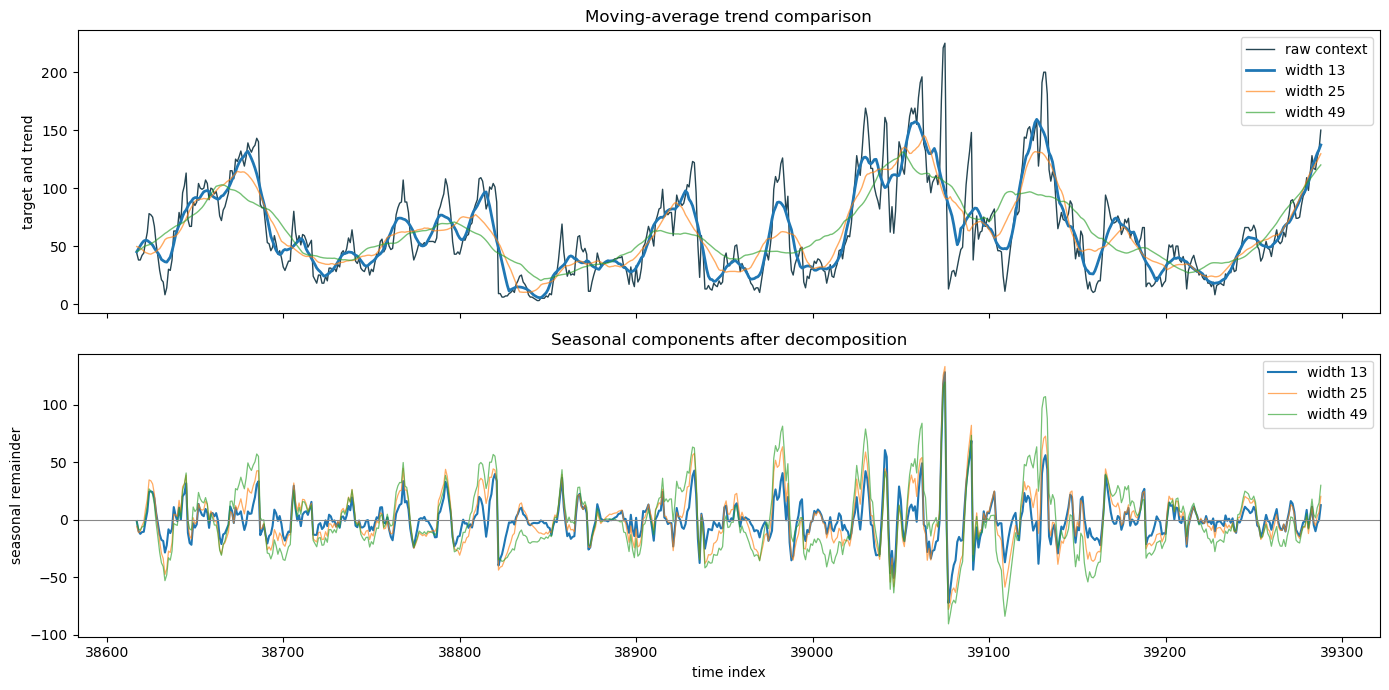

In [26]:
def moving_average(values, width):
    radius = width // 2
    padded = np.pad(values, (radius, radius), mode="edge")
    return np.convolve(padded, np.ones(width) / width, mode="valid")

example = target_values[TRAIN_END - config.input_length:TRAIN_END]
time_index = train_df["time_idx"].to_numpy()[TRAIN_END - config.input_length:TRAIN_END]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(time_index, example, color="#264653", linewidth=1, label="raw context")

for width in WIDTHS:
    trend = moving_average(example, width)
    seasonal = example - trend
    selected = width == selected_width
    axes[0].plot(time_index, trend, linewidth=2 if selected else 1, alpha=1 if selected else 0.65, label=f"width {width}")
    axes[1].plot(time_index, seasonal, linewidth=1.5 if selected else 0.9, alpha=1 if selected else 0.65, label=f"width {width}")

axes[0].set_ylabel("target and trend")
axes[0].set_title("Moving-average trend comparison")
axes[0].legend()
axes[1].axhline(0, color="#888888", linewidth=0.8)
axes[1].set_xlabel("time index")
axes[1].set_ylabel("seasonal remainder")
axes[1].set_title("Seasonal components after decomposition")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "decomposition_widths.png", dpi=300, bbox_inches="tight")
plt.show()

## External-Data Ablation

The selected complete model is compared against an ablated version with all external variables removed.

In [27]:
external_records = width_results[width_results["moving_avg"] == selected_width].to_dict("records")
external_config = replace(config, moving_avg=selected_width, external_dim=10)
external_result, _, _, _ = run_experiment(f"external_width_{selected_width}_seed_2", external_config, seed=2, use_external=True)
external_records.append(external_result)

target_config = replace(config, moving_avg=selected_width, external_dim=0)
for seed in EXTERNAL_SEEDS:
    result, _, _, _ = run_experiment(f"target_only_seed_{seed}", target_config, seed, use_external=False)
    external_records.append(result)

external_results = pd.DataFrame(external_records)
external_results.to_csv(METRIC_DIR / "external_ablation_runs.csv", index=False)
external_results


Experiment: external_width_13_seed_2
Seed: 2
Moving-average width: 13
External data: True


external_width_13_seed_2 | epoch 1/3: 100%|██████████| 601/601 [00:29<00:00, 20.21it/s, mse=0.65238, rmse=73.6098]


Epoch 1: train MSE=0.65238, train RMSE=73.6098, validation MSE=0.47736, validation RMSE=62.5371


external_width_13_seed_2 | epoch 2/3: 100%|██████████| 601/601 [00:41<00:00, 14.48it/s, mse=0.58101, rmse=69.4668]


Epoch 2: train MSE=0.58101, train RMSE=69.4668, validation MSE=0.55634, validation RMSE=67.6137


...

target_only_seed_2 | epoch 2/3: 100%|██████████| 601/601 [00:40<00:00, 14.66it/s, mse=1.04086, rmse=92.9777]


Epoch 2: train MSE=1.04086, train RMSE=92.9777, validation MSE=0.94059, validation RMSE=88.3861


target_only_seed_2 | epoch 3/3: 100%|██████████| 601/601 [00:33<00:00, 17.92it/s, mse=1.03919, rmse=92.9033]


Epoch 3: train MSE=1.03919, train RMSE=92.9033, validation MSE=0.93563, validation RMSE=88.1529


,train_mse_loss,train_rmse,validation_mse_loss,validation_rmse,validation_mae,validation_smape,best_epoch,parameters,training_seconds,name,seed,moving_avg,use_external,checkpoint
0,0.660314,74.055784,0.470268,61.605270,45.050003,66.779053,1,42561,126.474193,external_width_13_seed_0,0,13,True,checkpoints\external_width_13_seed_0.pt
1,0.681757,75.248661,0.478578,62.436573,44.632732,65.221428,1,42561,135.316767,external_width_13_seed_1,1,13,True,checkpoints\external_width_13_seed_1.pt
2,0.652384,73.609789,0.477357,62.537117,47.063847,64.920212,1,42561,126.222459,external_width_13_seed_2,2,13,True,checkpoints\external_width_13_seed_2.pt
3,1.044767,93.152294,0.939642,88.341553,66.469025,78.331230,1,41921,145.773202,target_only_seed_0,0,13,False,checkpoints\target_only_seed_0.pt
4,1.039762,92.928904,0.941383,88.423340,66.356743,78.646149,3,41921,150.703648,target_only_seed_1,1,13,False,checkpoints\target_only_seed_1.pt
5,1.039189,92.903312,0.935632,88.152870,66.501816,78.282310,3,41921,123.067749,target_only_seed_2,2,13,False,checkpoints\target_only_seed_2.pt


In [28]:
external_summary = external_results.groupby("use_external", as_index=False).agg(train_mse_mean=("train_mse_loss", "mean"), train_mse_std=("train_mse_loss", "std"), train_rmse_mean=("train_rmse", "mean"), train_rmse_std=("train_rmse", "std"), validation_mse_mean=("validation_mse_loss", "mean"), validation_mse_std=("validation_mse_loss", "std"), validation_rmse_mean=("validation_rmse", "mean"), validation_rmse_std=("validation_rmse", "std"), validation_mae_mean=("validation_mae", "mean"), validation_mae_std=("validation_mae", "std"), validation_smape_mean=("validation_smape", "mean"), validation_smape_std=("validation_smape", "std"), parameters=("parameters", "first"), best_epoch_mean=("best_epoch", "mean"), training_seconds_mean=("training_seconds", "mean"))
target_by_seed = external_results[external_results["use_external"] == False].set_index("seed")
external_by_seed = external_results[external_results["use_external"] == True].set_index("seed")
external_wins = int((external_by_seed.loc[EXTERNAL_SEEDS, "validation_rmse"] < target_by_seed.loc[EXTERNAL_SEEDS, "validation_rmse"]).sum())
target_mean = float(external_summary.loc[external_summary["use_external"] == False, "validation_rmse_mean"].iloc[0])
external_mean = float(external_summary.loc[external_summary["use_external"] == True, "validation_rmse_mean"].iloc[0])
selected_external = external_mean < target_mean and external_wins >= 2
external_summary["selected"] = external_summary["use_external"] == selected_external
external_summary.to_csv(METRIC_DIR / "external_ablation.csv", index=False)
print("External-data wins across matched seeds:", external_wins, "of", len(EXTERNAL_SEEDS))
print("Selected external-data usage:", selected_external)
external_summary.round(4)

External-data wins across matched seeds: 3 of 3
Selected external-data usage: True


,use_external,train_mse_mean,train_mse_std,train_rmse_mean,train_rmse_std,validation_mse_mean,validation_mse_std,validation_rmse_mean,validation_rmse_std,validation_mae_mean,validation_mae_std,validation_smape_mean,validation_smape_std,parameters,best_epoch_mean,training_seconds_mean,selected
0,False,1.0412,0.0031,92.9948,0.1370,0.9389,0.0029,88.3059,0.1387,66.4425,0.0761,78.4199,0.1975,41921,2.3333,139.8482,False
1,True,0.6648,0.0152,74.3047,0.8473,0.4754,0.0045,62.1930,0.5115,45.5822,1.3000,65.6402,0.9977,42561,1.0000,129.3378,True


C:\Users\Syed Daniyal\AppData\Local\Temp\ipykernel_22804\1545499026.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(record["checkpoint"], map_loc

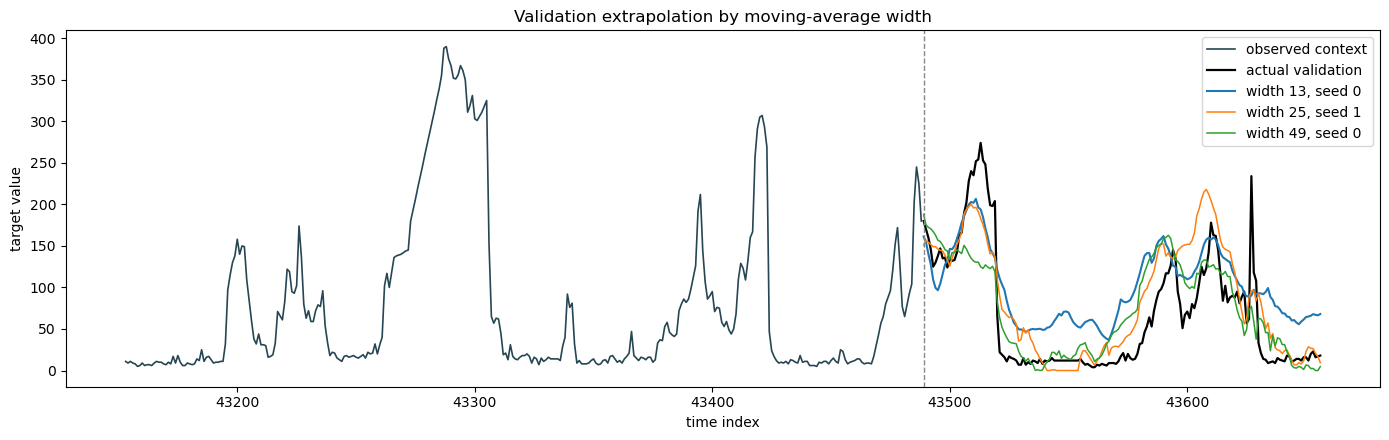

C:\Users\Syed Daniyal\AppData\Local\Temp\ipykernel_22804\1545499026.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(record["checkpoint"], map_loc

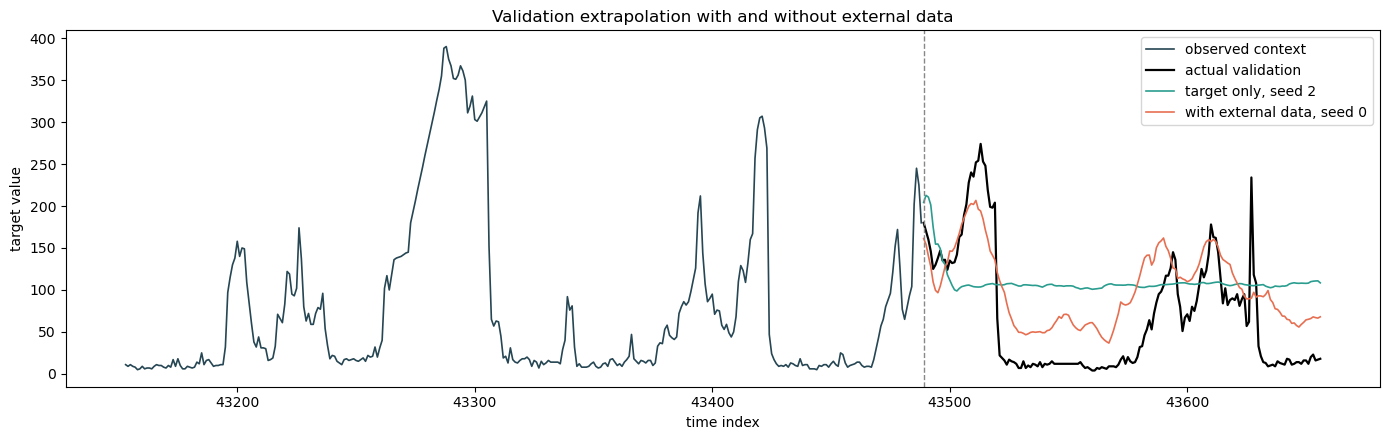

In [29]:
def evaluate_checkpoint(record):
    checkpoint = torch.load(record["checkpoint"], map_location=device)
    model_config = replace(config, moving_avg=int(record["moving_avg"]), external_dim=10 if record["use_external"] else 0)
    model = Autoformer(model_config).to(device)
    model.load_state_dict(checkpoint["best_model_state"])
    _, loader = build_loaders(model_config, int(record["seed"]))
    trainer = AutoformerTrainer(model, model_config, target_scaler, external_scaler, Path(record["checkpoint"]), device, record["name"])
    return trainer.evaluate(loader, bool(record["use_external"]))

last_origin = validation_origins[-1]
display_context = min(336, config.input_length)
all_time = train_df["time_idx"].to_numpy()
context_time = all_time[last_origin - display_context:last_origin]
validation_time = all_time[last_origin:last_origin + config.pred_length]
observed_context = target_values[last_origin - display_context:last_origin]
actual_validation = target_values[last_origin:last_origin + config.pred_length]

width_representatives = []
width_predictions = {}
for width in WIDTHS:
    width_runs = width_results[width_results["moving_avg"] == width]
    representative_index = width_runs["validation_rmse"].idxmin()
    representative = width_runs.loc[representative_index].to_dict()
    representative["use_external"] = True
    width_representatives.append(representative)
    _, predictions, _ = evaluate_checkpoint(representative)
    width_predictions[width] = predictions[-1, :, 0]

pd.DataFrame(width_representatives).to_csv(METRIC_DIR / "width_representatives.csv", index=False)
fig, axis = plt.subplots(figsize=(14, 4.5))
axis.plot(context_time, observed_context, color="#264653", linewidth=1.2, label="observed context")
axis.plot(validation_time, actual_validation, color="#000000", linewidth=1.6, label="actual validation")
for representative in width_representatives:
    width = int(representative["moving_avg"])
    seed = int(representative["seed"])
    axis.plot(validation_time, width_predictions[width], linewidth=1.5 if width == selected_width else 1.1, label=f"width {width}, seed {seed}")
axis.axvline(validation_time[0], color="#888888", linestyle="--", linewidth=1)
axis.set_xlabel("time index")
axis.set_ylabel("target value")
axis.set_title("Validation extrapolation by moving-average width")
axis.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "validation_width_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

best_target_seed = int(target_by_seed["validation_rmse"].idxmin())
best_external_seed = int(external_by_seed["validation_rmse"].idxmin())
best_target_record = {**target_by_seed.loc[best_target_seed].to_dict(), "seed": best_target_seed, "use_external": False}
best_external_record = {**external_by_seed.loc[best_external_seed].to_dict(), "seed": best_external_seed, "use_external": True}
_, target_predictions, _ = evaluate_checkpoint(best_target_record)
_, external_predictions, _ = evaluate_checkpoint(best_external_record)
pd.DataFrame([best_target_record, best_external_record]).to_csv(METRIC_DIR / "external_representatives.csv", index=False)

fig, axis = plt.subplots(figsize=(14, 4.5))
axis.plot(context_time, observed_context, color="#264653", linewidth=1.2, label="observed context")
axis.plot(validation_time, actual_validation, color="#000000", linewidth=1.6, label="actual validation")
axis.plot(validation_time, target_predictions[-1, :, 0], color="#2a9d8f", linewidth=1.2, label=f"target only, seed {best_target_seed}")
axis.plot(validation_time, external_predictions[-1, :, 0], color="#e76f51", linewidth=1.2, label=f"with external data, seed {best_external_seed}")
axis.axvline(validation_time[0], color="#888888", linestyle="--", linewidth=1)
axis.set_xlabel("time index")
axis.set_ylabel("target value")
axis.set_title("Validation extrapolation with and without external data")
axis.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "validation_external_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Final Model Training

The selected configuration is retrained on every observed target value. The training length is the median best epoch from its three validation-seed runs.

In [34]:
selected_runs = external_results[external_results["use_external"] == selected_external]
final_epochs = 3
final_config = replace(config, moving_avg=selected_width, external_dim=10 if selected_external else 0)
final_target_scaler = DatasetScaler().fit(target_values[:, None])
final_external_scaler = ExternalScaler().fit(external_values[:len(target_values)])
final_scaled_target = final_target_scaler.transform(target_values[:, None])
final_scaled_external = final_external_scaler.transform(external_values)
final_origins = np.arange(final_config.input_length, len(target_values) - final_config.pred_length + 1, final_config.training_stride)
final_dataset = TimeSeriesDataset(final_scaled_target, final_scaled_external, final_config.input_length, final_config.pred_length, final_origins)
final_generator = torch.Generator().manual_seed(0)
final_loader = DataLoader(final_dataset, batch_size=final_config.batch_size, shuffle=True, generator=final_generator, pin_memory=device.type == "cuda")
print("Final moving-average width:", selected_width)
print("Final external-data usage:", selected_external)
print("Final training epochs:", final_epochs)

Final moving-average width: 13
Final external-data usage: True
Final training epochs: 3


In [35]:
def train_final_model(config, train_loader, epochs, use_external, resume=False):
    set_seed(0)
    model = Autoformer(config).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, betas=(0.9, 0.999), weight_decay=0)
    checkpoint_path = CHECKPOINT_DIR / "final_model.pt"
    start_epoch, training_seconds = 0, 0
    history = {"train_mse_loss": [], "train_rmse": []}

    if resume and checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        start_epoch = checkpoint["epoch"] + 1
        history = checkpoint["history"]
        if isinstance(history, list):
            history = {"train_mse_loss": history, "train_rmse": [math.sqrt(value) * float(final_target_scaler.std.squeeze()) for value in history]}
        training_seconds = checkpoint["training_seconds"]

    for epoch in range(start_epoch, epochs):
        start_time = time.perf_counter()
        model.train()
        total_squared_error, total_points = 0, 0
        target_scale = float(final_target_scaler.std.squeeze())
        progress = tqdm(train_loader, desc=f"final_model | epoch {epoch + 1}/{epochs}")

        for past_values, past_external, future_external, target in progress:
            past_values = past_values.to(device, non_blocking=True)
            past_external = past_external.to(device, non_blocking=True)
            future_external = future_external.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(past_values, past_external, future_external) if use_external else model(past_values)
            loss = criterion(prediction, target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.gradient_clip)
            optimizer.step()
            total_squared_error += torch.sum((prediction.detach() - target) ** 2).item()
            total_points += target.numel()
            running_mse = total_squared_error / total_points
            progress.set_postfix(mse=f"{running_mse:.5f}", rmse=f"{math.sqrt(running_mse) * target_scale:.5f}")

        epoch_mse = total_squared_error / total_points
        epoch_rmse = math.sqrt(epoch_mse) * target_scale
        history["train_mse_loss"].append(epoch_mse)
        history["train_rmse"].append(epoch_rmse)
        training_seconds += time.perf_counter() - start_time
        checkpoint = {"model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(), "epoch": epoch, "history": history, "training_seconds": training_seconds, "configuration": asdict(config), "target_scaler": final_target_scaler.state_dict(), "external_scaler": final_external_scaler.state_dict()}
        torch.save(checkpoint, checkpoint_path)
        print(f"Final epoch {epoch + 1}: train MSE={epoch_mse:.5f}, train RMSE={epoch_rmse:.5f}")

    return model, history, training_seconds

final_model, final_history, final_training_seconds = train_final_model(final_config, final_loader, final_epochs, selected_external, resume=RESUME)
final_history_df = pd.DataFrame(final_history, index=np.arange(1, len(final_history["train_mse_loss"]) + 1))
final_history_df.index.name = "epoch"
final_history_df.to_csv(METRIC_DIR / "final_training_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(final_history_df.index, final_history_df["train_mse_loss"], label="train MSE")
axes[0].set(xlabel="epoch", ylabel="MSE loss", title="Final training MSE")
axes[1].plot(final_history_df.index, final_history_df["train_rmse"], label="train RMSE")
axes[1].set(xlabel="epoch", ylabel="RMSE", title="Final training RMSE")
for axis in axes:
    axis.legend()
fig.tight_layout()
fig.savefig(TRAINING_FIGURE_DIR / "final_training.png", dpi=300, bbox_inches="tight")
plt.close(fig)

final_model | epoch 1/3:   0%|          | 0/670 [00:00<?, ?it/s]

final_model | epoch 1/3: 100%|██████████| 670/670 [00:46<00:00, 14.55it/s, mse=0.64641, rmse=73.03022]


Final epoch 1: train MSE=0.64641, train RMSE=73.03022


final_model | epoch 2/3: 100%|██████████| 670/670 [00:49<00:00, 13.43it/s, mse=0.56505, rmse=68.27956]


Final epoch 2: train MSE=0.56505, train RMSE=68.27956


final_model | epoch 3/3: 100%|██████████| 670/670 [00:50<00:00, 13.34it/s, mse=0.52112, rmse=65.57156]


Final epoch 3: train MSE=0.52112, train RMSE=65.57156


## Final 168-Step Forecast

In [32]:
final_model.eval()
context_start = len(target_values) - final_config.input_length
past_values = torch.from_numpy(final_scaled_target[context_start:len(target_values)]).unsqueeze(0).to(device)
past_external = torch.from_numpy(final_scaled_external[context_start:len(target_values)]).unsqueeze(0).to(device)
future_external = torch.from_numpy(final_scaled_external[len(target_values):len(target_values) + final_config.pred_length]).unsqueeze(0).to(device)

with torch.no_grad():
    scaled_forecast = final_model(past_values, past_external, future_external) if selected_external else final_model(past_values)

forecast = final_target_scaler.inverse_transform(scaled_forecast.cpu().numpy().reshape(-1, 1)).reshape(-1)
forecast = np.clip(forecast, 0, None)
assert len(forecast) == 168
assert np.isfinite(forecast).all()
prediction_text = ",".join(f"{value:.6f}" for value in forecast)
(OUTPUT_DIR / "predictions.txt").write_text(prediction_text, encoding="utf-8")

final_configuration = {**asdict(final_config), "use_external": selected_external, "training_epochs": final_epochs, "parameters": count_parameters(final_model), "training_seconds": final_training_seconds}
pd.DataFrame([final_configuration]).to_csv(METRIC_DIR / "final_configuration.csv", index=False)
print("Forecast values:", len(forecast))
print("Trainable parameters:", count_parameters(final_model))
print("Predictions saved to:", OUTPUT_DIR / "predictions.txt")

Forecast values: 168
Trainable parameters: 42561
Predictions saved to: outputs\predictions.txt


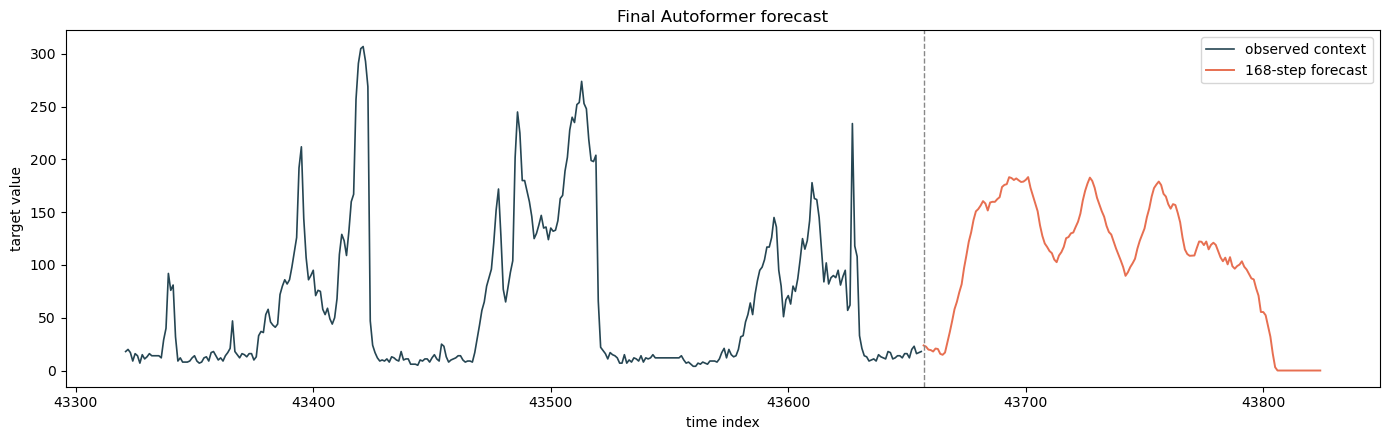

In [33]:
display_context = min(336, final_config.input_length)
context_time = train_df["time_idx"].to_numpy()[-display_context:]
forecast_time = test_df["time_idx"].to_numpy()
fig, axis = plt.subplots(figsize=(14, 4.5))
axis.plot(context_time, target_values[-display_context:], color="#264653", linewidth=1.2, label="observed context")
axis.plot(forecast_time, forecast, color="#e76f51", linewidth=1.4, label="168-step forecast")
axis.axvline(forecast_time[0], color="#888888", linestyle="--", linewidth=1)
axis.set_xlabel("time index")
axis.set_ylabel("target value")
axis.set_title("Final Autoformer forecast")
axis.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "final_forecast.png", dpi=300, bbox_inches="tight")
plt.show()